In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

import os
import warnings
warnings.filterwarnings("ignore")

db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"

conn = sqlite3.connect(db_path)

yield_train = pd.read_sql_query(
    "SELECT * FROM agri_yield_train_selected",
    conn
)

print("Data loaded successfully!")
print("Dataset shape:", yield_train.shape)
print("\nFirst 5 rows:")
display(yield_train.head())

Data loaded successfully!
Dataset shape: (10000, 11)

First 5 rows:


,NDVI_Temperature,OrganicMatter_Sand,Temperature_Rainfall,sand_pct,NDVI_Rainfall,soil_ph,organic_matter,Humidity_Rainfall,Temperature_Humidity,rainfall,yield
0,11.592,110.656,2777.04,41.6,50.692,6.25,2.66,7714.0,1764.0,110.2,4105.8
1,15.871,147.132,3397.47,40.2,74.517,6.70,3.66,9851.4,2098.2,126.3,4247.8
2,17.664,138.000,3019.44,40.0,70.016,7.21,3.45,7220.4,1821.6,109.4,4021.8
3,18.352,141.112,4596.88,56.9,96.286,5.73,2.48,12268.7,2338.4,155.3,4326.8
4,15.500,110.466,4315.00,30.6,107.012,6.88,3.61,13808.0,2000.0,172.6,3708.0


In [2]:
print("Dataset shape:", yield_train.shape)

print("\nColumn names:")
print(yield_train.columns.tolist())

print("\nData types:")
print(yield_train.dtypes)

print("\nMissing values:")
print(yield_train.isnull().sum())

print("\nDuplicate rows:", yield_train.duplicated().sum())

print("\nTarget summary:")
display(yield_train["yield"].describe())

Dataset shape: (10000, 11)

Column names:
['NDVI_Temperature', 'OrganicMatter_Sand', 'Temperature_Rainfall', 'sand_pct', 'NDVI_Rainfall', 'soil_ph', 'organic_matter', 'Humidity_Rainfall', 'Temperature_Humidity', 'rainfall', 'yield']

Data types:
NDVI_Temperature        float64
OrganicMatter_Sand      float64
Temperature_Rainfall    float64
sand_pct                float64
NDVI_Rainfall           float64
soil_ph                 float64
organic_matter          float64
Humidity_Rainfall       float64
Temperature_Humidity    float64
rainfall                float64
yield                   float64
dtype: object

Missing values:
NDVI_Temperature        0
OrganicMatter_Sand      0
Temperature_Rainfall    0
sand_pct                0
NDVI_Rainfall           0
soil_ph                 0
organic_matter          0
Humidity_Rainfall       0
Temperature_Humidity    0
rainfall                0
yield                   0
dtype: int64

Duplicate rows: 0

Target summary:


count    10000.000000
mean      4251.976400
std        436.533109
min       3500.200000
25%       3868.050000
50%       4257.150000
75%       4638.325000
max       5000.000000
Name: yield, dtype: float64

In [3]:
# Separate input features and target

X = yield_train.drop(columns=["yield"])
y = yield_train["yield"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget name:", y.name)

print("\nAny missing values in X:", X.isnull().sum().sum())
print("Any missing values in y:", y.isnull().sum())

Features shape: (10000, 10)
Target shape: (10000,)

Input features:
['NDVI_Temperature', 'OrganicMatter_Sand', 'Temperature_Rainfall', 'sand_pct', 'NDVI_Rainfall', 'soil_ph', 'organic_matter', 'Humidity_Rainfall', 'Temperature_Humidity', 'rainfall']

Target name: yield

Any missing values in X: 0
Any missing values in y: 0


In [4]:
# Create 5-fold cross-validation

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Number of folds:", cv.get_n_splits())
print("Validation strategy: 5-fold KFold")
print("Shuffle enabled: True")
print("Random state: 42")

Number of folds: 5
Validation strategy: 5-fold KFold
Shuffle enabled: True
Random state: 42


In [5]:
models = {
    "Dummy Regressor": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyRegressor(strategy="mean"))
    ]),

    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(random_state=42))
    ])
}

# Add XGBoost if installed
try:
    from xgboost import XGBRegressor

    models["XGBoost"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBRegressor(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            random_state=42,
            n_jobs=-1,
            objective="reg:squarederror"
        ))
    ])

    print("XGBoost is available.")

except ImportError:
    print("XGBoost is not installed. Other models will still run.")

print("\nModels to compare:")
for name in models:
    print(name)

XGBoost is available.

Models to compare:
Dummy Regressor
Linear Regression
Decision Tree
Random Forest
Gradient Boosting
XGBoost


In [6]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

print("Evaluation metrics:")
print("MAE  - lower is better")
print("RMSE - lower is better")
print("R2   - higher is better")

Evaluation metrics:
MAE  - lower is better
RMSE - lower is better
R2   - higher is better


In [7]:
results = []

for name, model in models.items():

    print("Evaluating:", name)

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    results.append({
        "Model": name,
        "Mean_CV_MAE": -scores["test_MAE"].mean(),
        "Std_CV_MAE": scores["test_MAE"].std(),
        "Mean_CV_RMSE": -scores["test_RMSE"].mean(),
        "Std_CV_RMSE": scores["test_RMSE"].std(),
        "Mean_CV_R2": scores["test_R2"].mean(),
        "Std_CV_R2": scores["test_R2"].std()
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Mean_CV_R2",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Evaluating: Dummy Regressor
Evaluating: Linear Regression
Evaluating: Decision Tree
Evaluating: Random Forest
Evaluating: Gradient Boosting
Evaluating: XGBoost


,Model,Mean_CV_MAE,Std_CV_MAE,Mean_CV_RMSE,Std_CV_RMSE,Mean_CV_R2,Std_CV_R2
0,Dummy Regressor,378.8920,5.3958,436.5174,5.0271,-0.0004,0.0004
1,Linear Regression,378.7503,5.4351,436.6612,5.1069,-0.0011,0.0009
2,Gradient Boosting,380.0580,6.0658,438.6452,5.7438,-0.0102,0.0050
3,Random Forest,384.7275,6.2669,446.2336,6.4066,-0.0455,0.0129
4,XGBoost,384.8386,4.8350,446.8623,4.7182,-0.0485,0.0074
5,Decision Tree,512.3598,6.8853,626.8857,5.5233,-1.0635,0.0176


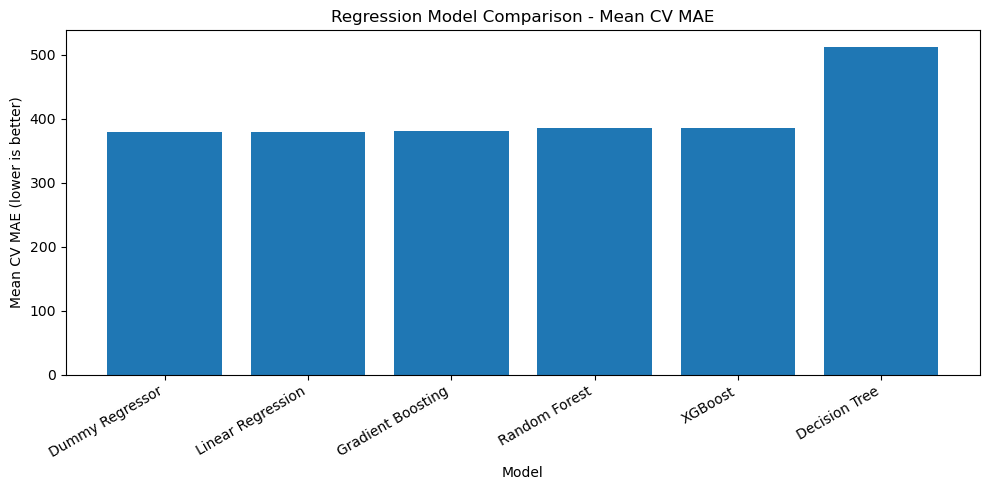

In [8]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Mean_CV_MAE"]
)

plt.title("Regression Model Comparison - Mean CV MAE")
plt.xlabel("Model")
plt.ylabel("Mean CV MAE (lower is better)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

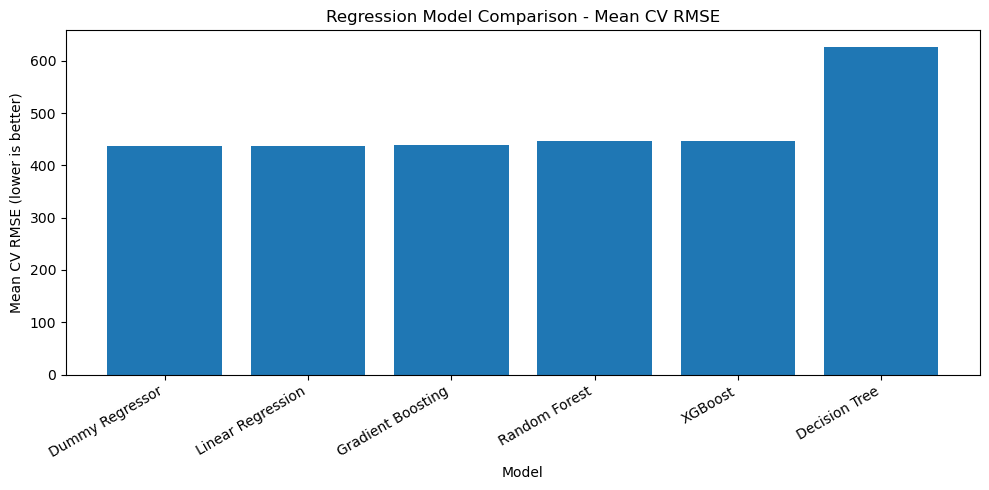

In [9]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Mean_CV_RMSE"]
)

plt.title("Regression Model Comparison - Mean CV RMSE")
plt.xlabel("Model")
plt.ylabel("Mean CV RMSE (lower is better)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

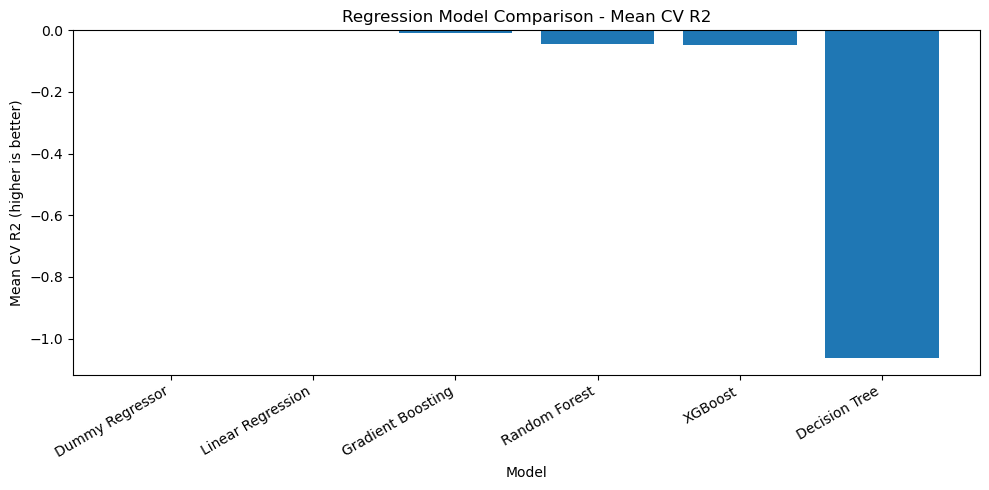

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Mean_CV_R2"]
)

plt.title("Regression Model Comparison - Mean CV R2")
plt.xlabel("Model")
plt.ylabel("Mean CV R2 (higher is better)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [11]:
best_model_name = results_df.iloc[0]["Model"]

print("Best candidate by mean CV R2:", best_model_name)

print("\nPerformance:")
display(
    results_df.loc[
        results_df["Model"] == best_model_name
    ].round(4)
)

Best candidate by mean CV R2: Dummy Regressor

Performance:


,Model,Mean_CV_MAE,Std_CV_MAE,Mean_CV_RMSE,Std_CV_RMSE,Mean_CV_R2,Std_CV_R2
0,Dummy Regressor,378.892,5.3958,436.5174,5.0271,-0.0004,0.0004


In [12]:
output_dir = "stage15_outputs"
os.makedirs(output_dir, exist_ok=True)

results_path = os.path.join(
    output_dir,
    "regression_model_comparison.csv"
)

results_df.to_csv(results_path, index=False)

print("Results saved to:", results_path)

Results saved to: stage15_outputs\regression_model_comparison.csv


In [13]:
best_result = results_df.iloc[0]

summary = pd.DataFrame([{
    "Selected_Model": best_result["Model"],
    "Mean_CV_MAE": best_result["Mean_CV_MAE"],
    "Mean_CV_RMSE": best_result["Mean_CV_RMSE"],
    "Mean_CV_R2": best_result["Mean_CV_R2"],
    "Selection_Basis": "Highest mean 5-fold CV R2"
}])

summary_path = os.path.join(
    output_dir,
    "best_regression_candidate.csv"
)

summary.to_csv(summary_path, index=False)

display(summary.round(4))
print("Candidate summary saved to:", summary_path)

,Selected_Model,Mean_CV_MAE,Mean_CV_RMSE,Mean_CV_R2,Selection_Basis
0,Dummy Regressor,378.892,436.5174,-0.0004,Highest mean 5-fold CV R2


Candidate summary saved to: stage15_outputs\best_regression_candidate.csv


In [14]:
print("STAGE 15: REGRESSION MODEL COMPARISON")
print("-" * 45)

print("Training records:", len(y))
print("Input features:", X.shape[1])
print("Cross-validation folds:", cv.get_n_splits())
print("Models evaluated:", len(models))

print("\nBest candidate:", best_model_name)

print("\nTop 3 models by mean CV R2:")
display(results_df.head(3).round(4))

print("\nOutput files:")
print("- stage15_outputs/regression_model_comparison.csv")
print("- stage15_outputs/best_regression_candidate.csv")

STAGE 15: REGRESSION MODEL COMPARISON
---------------------------------------------
Training records: 10000
Input features: 10
Cross-validation folds: 5
Models evaluated: 6

Best candidate: Dummy Regressor

Top 3 models by mean CV R2:


,Model,Mean_CV_MAE,Std_CV_MAE,Mean_CV_RMSE,Std_CV_RMSE,Mean_CV_R2,Std_CV_R2
0,Dummy Regressor,378.8920,5.3958,436.5174,5.0271,-0.0004,0.0004
1,Linear Regression,378.7503,5.4351,436.6612,5.1069,-0.0011,0.0009
2,Gradient Boosting,380.0580,6.0658,438.6452,5.7438,-0.0102,0.0050



Output files:
- stage15_outputs/regression_model_comparison.csv
- stage15_outputs/best_regression_candidate.csv
